# Arua City Emergency Dispatch & Routing: Algorithmic Decision-Support Prototype
**Muni University | Algorithms group project**

**Pipeline we are building (one idea, five components):**

```
Emergency arrives -> PRIORITISE -> SELECT ambulance -> ROUTE to patient & hospital -> EVALUATE
   (heap + aging)     (multi-target Dijkstra)   (Dijkstra vs A*)      (time, complexity, quality)
```

**How to read this notebook:** every section starts with a short *Concept* box (the computer-science idea), then the code, then an *Observation* you should be able to explain in your own words. If you cannot explain a cell, do not submit it.

**Honest data note:** the dataset is *realistically simulated*. The coordinates are not real GPS points, and the hospital names are placeholders. Replace them with surveyed data if the authority provides it. The code does not change.

## 0. Setup and modelling assumptions

**Concept: assumptions are part of the algorithm.** Every model hides assumptions, so we state them. Changing one is a one-line edit.

| Assumption | Value | Why |
|---|---|---|
| Edge weight | **travel time in minutes** (not km) | Dispatchers care about time. A 1 km murram road can be slower than 2 km of tarmac |
| Arterial speed / local speed | 40 / 25 km/h | Typical urban ambulance speeds in a congested small city |
| Congestion | random multiplier 1.0 to 1.5 per road | Static snapshot of traffic |
| Time on scene | 5 min | Stabilising the patient |
| Hospital handover | 10 min | Ambulance blocked until patient is handed over |
| Ambulance after a job | waits at the hospital where it dropped the patient | Simplest realistic rule |
| Severity | 1 (minor) to 5 (critical) | Mirrors triage categories |

In [1]:
import heapq, math, random, time, os
from dataclasses import dataclass
from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt

INF = float("inf")
ARTERIAL_SPEED, LOCAL_SPEED = 40.0, 25.0     # km/h
MAX_SPEED = ARTERIAL_SPEED                    # used by the A* heuristic
SCENE_MIN, HANDOVER_MIN = 5.0, 10.0
DATA_DIR = "data"
pd.set_option("display.width", 140)

## 1. Data representation

**Concept: choose the data structure that matches how the data is *used*.**

| Entity | Structure | Why |
|---|---|---|
| Road network | **Adjacency list**: `dict[node] -> dict[neighbour] -> minutes` | Algorithms constantly ask "who are my neighbours?". A dict answers in O(deg) and edge lookup in O(1) |
| Coordinates | `dict[node] -> (x_km, y_km)` | Needed by A* heuristic and for drawing |
| Hospitals, stations, ambulances, requests | tables (CSV / DataFrame) and small `dataclass` objects | Records with attributes |
| Pending emergencies | **binary heap** (section 2) | Always need the most urgent one next |

**Why not an adjacency matrix?** For V junctions a matrix needs V^2 cells. At V = 5,000 that is 25 million cells, yet each junction has only about 3 to 4 roads, so almost all cells are empty. An adjacency list needs V + E cells, which is O(V) for road networks (they are *sparse* graphs).

### 1.1 Graph class

In [2]:
class Graph:
    """Undirected weighted graph stored as an adjacency list."""
    def __init__(self):
        self.adj = defaultdict(dict)     # u -> {v: minutes}
        self.coords = {}                 # u -> (x_km, y_km)

    def add_node(self, u, x, y):
        self.coords[u] = (x, y)
        self.adj[u]                       # touch so isolated nodes exist

    def add_edge(self, u, v, minutes):
        # keep the cheaper edge if a duplicate is added
        if minutes < self.adj[u].get(v, INF):
            self.adj[u][v] = minutes
            self.adj[v][u] = minutes

    def n_nodes(self): return len(self.coords)
    def n_edges(self): return sum(len(nb) for nb in self.adj.values()) // 2

    def euclid_km(self, u, v):
        (x1, y1), (x2, y2) = self.coords[u], self.coords[v]
        return math.hypot(x1 - x2, y1 - y2)

### 1.2 Generating a realistic road network

We lay junctions on a slightly jittered grid (like Arua's blocks), add arterial roads (faster) every 4th row and column, randomly remove some local roads (dead ends, blocked streets), and keep only the largest connected piece so every junction is reachable.

**Key detail for A\*:** a road's real length is *at least* the straight-line distance between its ends (roads bend). So `straight-line distance / max speed` can never overestimate travel time. That property is called **admissibility**, and it is what makes A\* provably optimal.

In [3]:
def generate_city(rows, cols, seed=42, spacing=0.5, drop_prob=0.12, diag_prob=0.08):
    """Return (node_coords, edges). Edge = (u, v, length_km, speed, road_class, congestion, minutes)."""
    rng = random.Random(seed)
    coords = {}
    for r in range(rows):
        for c in range(cols):
            nid = r * cols + c
            coords[nid] = (round(c * spacing + rng.uniform(-.15, .15) * spacing, 4),
                           round(r * spacing + rng.uniform(-.15, .15) * spacing, 4))

    def make_edge(u, v, arterial):
        (x1, y1), (x2, y2) = coords[u], coords[v]
        straight = math.hypot(x1 - x2, y1 - y2)
        length = straight * rng.uniform(1.0, 1.25)            # roads bend: length >= straight line
        speed = ARTERIAL_SPEED if arterial else LOCAL_SPEED
        cong = round(rng.uniform(1.0, 1.5), 3)
        return (u, v, round(length, 4), speed, "arterial" if arterial else "local", cong,
                round(length / speed * 60 * cong, 4))

    edges = []
    for r in range(rows):
        for c in range(cols):
            u = r * cols + c
            if c + 1 < cols:                                    # horizontal road
                art = (r % 4 == 0)
                if art or rng.random() > drop_prob: edges.append(make_edge(u, u + 1, art))
            if r + 1 < rows:                                    # vertical road
                art = (c % 4 == 0)
                if art or rng.random() > drop_prob: edges.append(make_edge(u, u + cols, art))
            if r + 1 < rows and c + 1 < cols and rng.random() < diag_prob:   # occasional diagonal
                edges.append(make_edge(u, u + cols + 1, False))

    # keep the largest connected component (BFS)
    nbrs = defaultdict(list)
    for e in edges: nbrs[e[0]].append(e[1]); nbrs[e[1]].append(e[0])
    seen, best = set(), set()
    for s in coords:
        if s in seen: continue
        comp, stack = {s}, [s]
        seen.add(s)
        while stack:
            u = stack.pop()
            for v in nbrs[u]:
                if v not in seen: seen.add(v); comp.add(v); stack.append(v)
        if len(comp) > len(best): best = comp
    coords = {u: p for u, p in coords.items() if u in best}
    edges = [e for e in edges if e[0] in best and e[1] in best]
    return coords, edges


def graph_from(coords, edges):
    g = Graph()
    for u, (x, y) in coords.items(): g.add_node(u, x, y)
    for e in edges: g.add_edge(e[0], e[1], e[6])
    return g

coords, edges = generate_city(10, 12, seed=42)
g_demo = graph_from(coords, edges)
print(f"Demo city: {g_demo.n_nodes()} junctions, {g_demo.n_edges()} roads, "
      f"average degree {2*g_demo.n_edges()/g_demo.n_nodes():.2f}")
print(f"Matrix would need {g_demo.n_nodes()**2:,} cells; adjacency list stores {2*g_demo.n_edges():,} entries.")

Demo city: 120 junctions, 209 roads, average degree 3.48
Matrix would need 14,400 cells; adjacency list stores 418 entries.


### 1.3 Building and saving the dataset (CSV files)

We place **5 hospitals**, **4 ambulance stations**, **8 ambulances** (2 per station) at well-spread junctions, and simulate **60 emergency calls over 4 hours** using a **Poisson arrival process** (the standard model for random independent arrivals: the gaps between calls are exponentially distributed). Severity follows a realistic skew: most calls are moderate, few are critical.

In [4]:
HOSPITAL_NAMES = ["Arua Regional Referral (sim)", "Rhema Hospital (sim)", "Ediofe Hospital (sim)",
                  "Hospital D (sim)", "Hospital E (sim)"]
STATION_NAMES = ["Central Station", "East Station", "West Station", "North Station"]
CATEGORIES = ["Road traffic accident", "Maternal emergency", "Cardiac event", "Stroke",
              "Burns", "Severe malaria (child)", "Fall / injury", "Other"]
SEV_LEVELS, SEV_PROBS = [1, 2, 3, 4, 5], [0.15, 0.25, 0.30, 0.20, 0.10]

def nearest_node(coords, fx, fy, used, width, height):
    tx, ty = fx * width, fy * height
    cands = [(math.hypot(x - tx, y - ty), u) for u, (x, y) in coords.items() if u not in used]
    return min(cands)[1]

def generate_emergencies(coords, n, horizon_min, seed):
    rng = random.Random(seed)
    nodes = sorted(coords)
    t, rows = 0.0, []
    rate = n / horizon_min
    for i in range(n):
        t += rng.expovariate(rate)                      # Poisson process
        rows.append(dict(request_id=f"E{i+1:03d}", arrival_min=round(t, 2),
                         node_id=rng.choice(nodes),
                         severity=rng.choices(SEV_LEVELS, SEV_PROBS)[0],
                         category=rng.choice(CATEGORIES)))
    return pd.DataFrame(rows)

def build_dataset(outdir=DATA_DIR, rows=10, cols=12, seed=42):
    os.makedirs(outdir, exist_ok=True)
    coords, edges = generate_city(rows, cols, seed)
    width, height = (cols - 1) * 0.5, (rows - 1) * 0.5
    used = set()
    hosp_pos = [(.50, .50), (.20, .25), (.80, .30), (.25, .80), (.80, .80)]
    stat_pos = [(.38, .42), (.68, .55), (.15, .60), (.58, .15)]
    hosp_nodes, stat_nodes = [], []
    for fx, fy in hosp_pos:
        n = nearest_node(coords, fx, fy, used, width, height); used.add(n); hosp_nodes.append(n)
    for fx, fy in stat_pos:
        n = nearest_node(coords, fx, fy, used, width, height); used.add(n); stat_nodes.append(n)

    ntype = {u: "junction" for u in coords}
    for n in hosp_nodes: ntype[n] = "hospital"
    for n in stat_nodes: ntype[n] = "station"
    pd.DataFrame([dict(node_id=u, x_km=x, y_km=y, node_type=ntype[u]) for u, (x, y) in coords.items()]
                 ).to_csv(f"{outdir}/nodes.csv", index=False)
    pd.DataFrame(edges, columns=["u", "v", "length_km", "speed_kmh", "road_class", "congestion", "travel_min"]
                 ).to_csv(f"{outdir}/roads.csv", index=False)
    pd.DataFrame([dict(hospital_id=f"H{i+1}", name=HOSPITAL_NAMES[i], node_id=n, beds_total=b)
                  for i, (n, b) in enumerate(zip(hosp_nodes, [250, 80, 120, 40, 30]))]
                 ).to_csv(f"{outdir}/hospitals.csv", index=False)
    pd.DataFrame([dict(station_id=f"S{i+1}", name=STATION_NAMES[i], node_id=n)
                  for i, n in enumerate(stat_nodes)]).to_csv(f"{outdir}/stations.csv", index=False)
    amb = [dict(ambulance_id=f"A{2*i+k+1}", station_id=f"S{i+1}", node_id=n)
           for i, n in enumerate(stat_nodes) for k in range(2)]
    pd.DataFrame(amb).to_csv(f"{outdir}/ambulances.csv", index=False)
    generate_emergencies(coords, 60, 240, seed=2026).to_csv(f"{outdir}/emergencies.csv", index=False)

build_dataset()
for f in sorted(os.listdir(DATA_DIR)):
    df = pd.read_csv(f"{DATA_DIR}/{f}")
    print(f"{f:18s} {len(df):4d} rows | columns: {list(df.columns)}")

ambulances.csv        8 rows | columns: ['ambulance_id', 'station_id', 'node_id']
emergencies.csv      60 rows | columns: ['request_id', 'arrival_min', 'node_id', 'severity', 'category']
hospitals.csv         5 rows | columns: ['hospital_id', 'name', 'node_id', 'beds_total']
nodes.csv           120 rows | columns: ['node_id', 'x_km', 'y_km', 'node_type']
roads.csv           209 rows | columns: ['u', 'v', 'length_km', 'speed_kmh', 'road_class', 'congestion', 'travel_min']
stations.csv          4 rows | columns: ['station_id', 'name', 'node_id']


In [5]:
def load_dataset(d=DATA_DIR):
    nodes = pd.read_csv(f"{d}/nodes.csv"); roads = pd.read_csv(f"{d}/roads.csv")
    g = Graph()
    for r in nodes.itertuples(): g.add_node(r.node_id, r.x_km, r.y_km)
    for r in roads.itertuples(): g.add_edge(r.u, r.v, r.travel_min)
    return (g, pd.read_csv(f"{d}/hospitals.csv"), pd.read_csv(f"{d}/stations.csv"),
            pd.read_csv(f"{d}/ambulances.csv"), pd.read_csv(f"{d}/emergencies.csv"), nodes)

G, hospitals_df, stations_df, ambulances_df, emergencies_df, nodes_df = load_dataset()
display(hospitals_df); display(emergencies_df.head(8))
print("Severity mix:", emergencies_df.severity.value_counts().sort_index().to_dict())

,hospital_id,name,node_id,beds_total
0,H1,Arua Regional Referral (sim),54,250
1,H2,Rhema Hospital (sim),26,80
2,H3,Ediofe Hospital (sim),45,120
3,H4,Hospital D (sim),87,40
4,H5,Hospital E (sim),93,30


,request_id,arrival_min,node_id,severity,category
0,E001,0.51,64,5,Maternal emergency
1,E002,9.13,114,3,Fall / injury
2,E003,15.25,70,4,Other
3,E004,20.81,75,3,Road traffic accident
4,E005,24.62,14,2,Maternal emergency
5,E006,27.01,104,4,Other
6,E007,31.56,26,2,Severe malaria (child)
7,E008,47.19,118,2,Fall / injury


Severity mix: {1: 5, 2: 16, 3: 22, 4: 12, 5: 5}


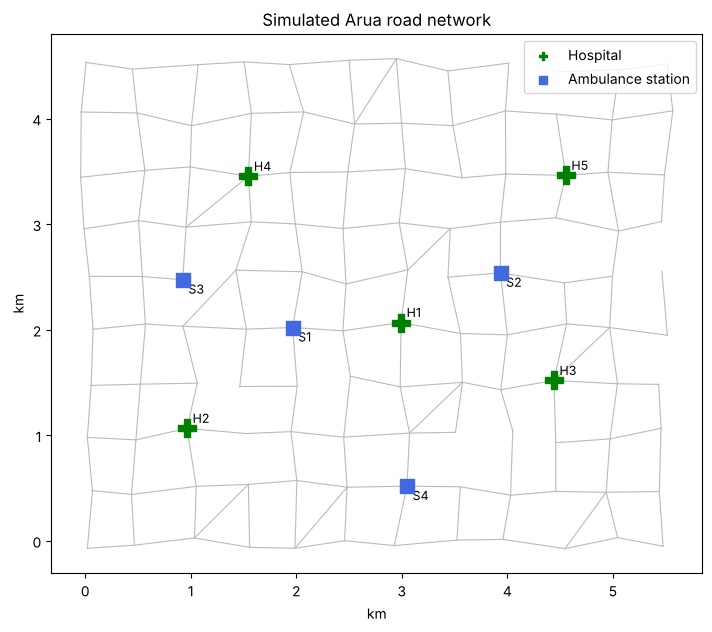

In [6]:
def draw_city(g, nodes_df, hospitals_df, stations_df, path=None, incident=None, title="Simulated Arua road network"):
    fig, ax = plt.subplots(figsize=(9, 7))
    for u, nb in g.adj.items():
        for v in nb:
            if u < v:
                (x1, y1), (x2, y2) = g.coords[u], g.coords[v]
                ax.plot([x1, x2], [y1, y2], color="#bbbbbb", lw=0.8, zorder=1)
    if path:
        ax.plot([g.coords[u][0] for u in path], [g.coords[u][1] for u in path], color="crimson", lw=3, zorder=3)
    for r in hospitals_df.itertuples():
        ax.scatter(*g.coords[r.node_id], marker="P", s=160, color="green", zorder=4)
        ax.annotate(r.hospital_id, g.coords[r.node_id], xytext=(4, 4), textcoords="offset points", fontsize=9)
    for r in stations_df.itertuples():
        ax.scatter(*g.coords[r.node_id], marker="s", s=90, color="royalblue", zorder=4)
        ax.annotate(r.station_id, g.coords[r.node_id], xytext=(4, -10), textcoords="offset points", fontsize=9)
    if incident is not None:
        ax.scatter(*g.coords[incident], marker="*", s=250, color="red", zorder=5)
    ax.set_title(title); ax.set_xlabel("km"); ax.set_ylabel("km"); ax.set_aspect("equal")
    ax.scatter([], [], marker="P", color="green", label="Hospital"); ax.scatter([], [], marker="s", color="royalblue", label="Ambulance station")
    ax.legend(loc="upper right"); plt.show()

draw_city(G, nodes_df, hospitals_df, stations_df)

## 2. Emergency prioritisation

**Concept: priority queue + aging.** We need an ordered "waiting room" where *insert* and *remove-the-most-urgent* are both fast. A sorted list makes insert O(n). A **binary heap** gives O(log n) for both.

**The scoring rule.** Severity alone causes **starvation**: a minor case could wait forever while critical ones keep arriving. So:

`priority(request, now) = SEVERITY_POINTS[severity] + AGING x (now - arrival)`

| Severity | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Points | 10 | 20 | 40 | 70 | 100 |

The points grow faster than linearly because the clinical gap between 4 and 5 is bigger than between 1 and 2. With `AGING = 1 point/minute`, a severity-1 case overtakes a fresh severity-5 case after 90 minutes of waiting, so nobody waits forever.

**The clever trick (worth understanding deeply).** Priorities change as time passes, so do we have to re-sort the heap every minute? No. Expand the formula:

`priority = POINTS + AGING*now - AGING*arrival = (POINTS - AGING*arrival) + AGING*now`

The term `AGING*now` is the *same for every request*, so it never changes the ranking. We store the **static key** `POINTS - AGING*arrival` once, and the heap stays correct forever. This works because aging is linear. A non-linear rule would need re-heapifying.

In [7]:
SEVERITY_POINTS = {1: 10, 2: 20, 3: 40, 4: 70, 5: 100}
AGING = 1.0   # priority points gained per minute waited

@dataclass(frozen=True)
class Emergency:
    rid: str
    arrival: float
    node: int
    severity: int
    category: str = ""

def priority_now(req, now, aging=AGING):
    return SEVERITY_POINTS[req.severity] + aging * (now - req.arrival)

class DispatchQueue:
    """Max-priority queue (Python's heapq is a min-heap, so we store the negated key).
    policy: 'priority' = severity + aging (proposed) | 'severity' = severity only | 'fifo' = first come first served."""
    def __init__(self, policy="priority", aging=AGING):
        self._h, self._n, self.policy, self.aging = [], 0, policy, aging

    def key(self, r):
        if self.policy == "fifo":     return -r.arrival
        if self.policy == "severity": return SEVERITY_POINTS[r.severity] - 1e-6 * r.arrival   # ties: earlier first
        return SEVERITY_POINTS[r.severity] - self.aging * r.arrival                          # static aging key

    def push(self, r):                                  # O(log n)
        heapq.heappush(self._h, (-self.key(r), self._n, r)); self._n += 1
    def pop(self):                                      # O(log n)
        return heapq.heappop(self._h)[2]
    def __len__(self): return len(self._h)

# --- Test 1: the heap order equals brute-force "highest priority_now" at any time ---
rng = random.Random(1)
for trial in range(200):
    reqs = [Emergency(f"T{i}", rng.uniform(0, 100), 0, rng.randint(1, 5)) for i in range(15)]
    now = 120.0
    q = DispatchQueue("priority")
    for r in reqs: q.push(r)
    assert q.pop() == max(reqs, key=lambda r: priority_now(r, now))
print("Test passed: static key gives the same winner as recomputing priorities (200 random trials).")

# --- Demonstration: aging prevents starvation ---
old_minor = Emergency("minor", arrival=0, node=0, severity=1)
new_critical = Emergency("critical", arrival=100, node=0, severity=5)
for now in (100, 150, 190, 200):
    print(f"t={now}: minor={priority_now(old_minor, now):6.1f}  critical={priority_now(new_critical, now):6.1f}")

Test passed: static key gives the same winner as recomputing priorities (200 random trials).
t=100: minor= 110.0  critical= 100.0
t=150: minor= 160.0  critical= 150.0
t=190: minor= 200.0  critical= 190.0
t=200: minor= 210.0  critical= 200.0


**Observation to explain:** at t=190 the minor case has finally overtaken the critical one (100 vs 100 at exactly that moment, then higher). That's the starvation guard. In the report you must *defend* the weights (10..100 and 1 point/min). Section 6 tests them experimentally.

## 3. Routing: two search algorithms

**Concept: shortest path in a weighted graph.**

**Dijkstra (1956).** Keep a min-heap of frontier nodes ordered by *distance travelled so far*. Repeatedly settle the closest unsettled node and relax its edges. It is correct for non-negative weights, and it explores in widening circles around the source, so it knows nothing about where the target is.

**A\* (1968).** Same loop, but order the heap by `f(n) = g(n) + h(n)`, where g is the cost so far and h is a *guess* of the remaining cost. Here `h = straight-line km / 40 km/h x 60`, the fastest conceivable travel time. If h never overestimates (admissible), A\* still returns the **optimal** path but wanders far less, because it is pulled toward the destination.

| | Dijkstra | A\* |
|---|---|---|
| Needs coordinates? | No | Yes |
| Time complexity (binary heap) | O((V+E) log V) | same worst case; typically far fewer nodes expanded |
| Optimal? | Yes | Yes if h is admissible |
| Space | O(V) | O(V) |

In [8]:
@dataclass
class Route:
    cost: float          # minutes
    path: list           # node ids from src to dst
    expanded: int        # nodes settled (a machine-independent work measure)

def _build_path(prev, src, dst):
    path, u = [dst], dst
    while u != src:
        u = prev[u]; path.append(u)
    return path[::-1]

def dijkstra(g, src, dst):
    dist, prev, done, pq, expanded = {src: 0.0}, {}, set(), [(0.0, src)], 0
    while pq:
        d, u = heapq.heappop(pq)
        if u in done: continue                  # stale heap entry (lazy deletion)
        done.add(u); expanded += 1
        if u == dst: return Route(d, _build_path(prev, src, dst), expanded)
        for v, w in g.adj[u].items():
            nd = d + w
            if nd < dist.get(v, INF):
                dist[v], prev[v] = nd, u
                heapq.heappush(pq, (nd, v))
    return Route(INF, [], expanded)

def geo_heuristic(g, dst):
    """Admissible: straight-line km at the fastest speed, converted to minutes."""
    return lambda u: g.euclid_km(u, dst) / MAX_SPEED * 60.0

def astar(g, src, dst, h=None):
    h = h or geo_heuristic(g, dst)
    gscore, prev, done, pq, expanded = {src: 0.0}, {}, set(), [(h(src), 0.0, src)], 0
    while pq:
        f, d, u = heapq.heappop(pq)
        if u in done: continue
        done.add(u); expanded += 1
        if u == dst: return Route(d, _build_path(prev, src, dst), expanded)
        for v, w in g.adj[u].items():
            nd = d + w
            if nd < gscore.get(v, INF):
                gscore[v], prev[v] = nd, u
                heapq.heappush(pq, (nd + h(v), nd, v))
    return Route(INF, [], expanded)

### 3.1 Verify by hand first (always test on a tiny case)

Graph: A-B = 1, B-C = 2, A-C = 5, C-D = 1, B-D = 6. By hand, the best A to D route is A, B, C, D = 1 + 2 + 1 = **4**. The direct-looking A, C, D costs 6 and A, B, D costs 7. If your code disagrees with your hand calculation, the code is wrong, not the paper.

In [9]:
tiny = Graph()
for n, xy in {"A": (0, 0), "B": (1, 0), "C": (2, 0), "D": (3, 0)}.items(): tiny.add_node(n, *xy)
for u, v, w in [("A","B",1), ("B","C",2), ("A","C",5), ("C","D",1), ("B","D",6)]: tiny.add_edge(u, v, w)

r1, r2 = dijkstra(tiny, "A", "D"), astar(tiny, "A", "D", h=lambda u: 0)
assert r1.cost == 4 and r1.path == ["A", "B", "C", "D"]
assert r2.cost == 4 and r2.path == ["A", "B", "C", "D"]
assert dijkstra(tiny, "A", "A").cost == 0
tiny.add_node("Z", 9, 9)                              # unreachable island
assert dijkstra(tiny, "A", "Z").cost == INF
print("Hand-verified tests passed:", r1.path, "cost", r1.cost)

# Now on the Arua network: both algorithms must agree on cost for every pair
rng = random.Random(5); ids = sorted(G.coords)
for _ in range(300):
    s, t = rng.sample(ids, 2)
    a, b = dijkstra(G, s, t), astar(G, s, t)
    assert abs(a.cost - b.cost) < 1e-9, (s, t, a.cost, b.cost)
print("300 random pairs: A* cost == Dijkstra cost (A* is optimal because the heuristic is admissible).")

Hand-verified tests passed: ['A', 'B', 'C', 'D'] cost 4.0
300 random pairs: A* cost == Dijkstra cost (A* is optimal because the heuristic is admissible).


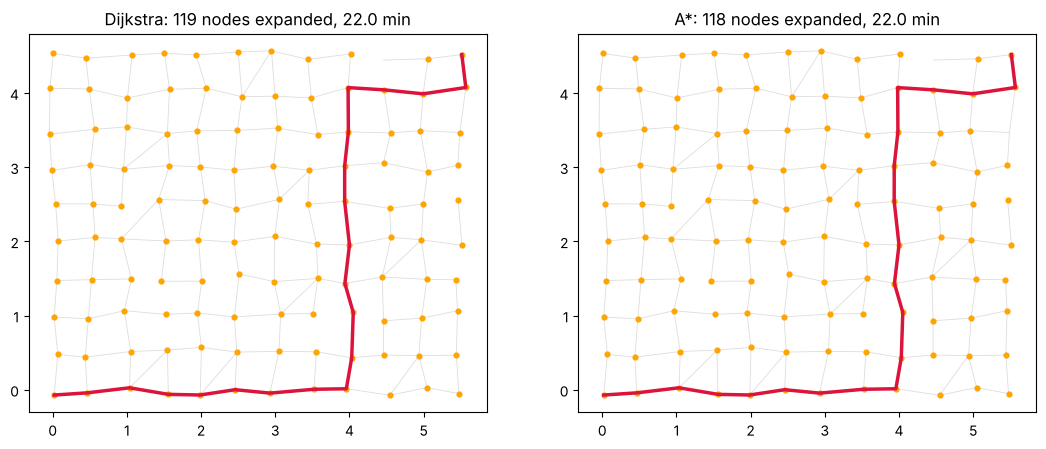

In [10]:
# Visual comparison on one long trip: which nodes does each algorithm *settle*?
def explored_nodes(g, src, dst, use_astar):
    h = geo_heuristic(g, dst) if use_astar else (lambda u: 0.0)
    gscore, done, pq = {src: 0.0}, [], [(h(src), 0.0, src)]
    seen = set()
    while pq:
        f, d, u = heapq.heappop(pq)
        if u in seen: continue
        seen.add(u); done.append(u)
        if u == dst: break
        for v, w in g.adj[u].items():
            if d + w < gscore.get(v, INF):
                gscore[v] = d + w; heapq.heappush(pq, (d + w + h(v), d + w, v))
    return done

src, dst = min(G.coords, key=lambda u: sum(G.coords[u])), max(G.coords, key=lambda u: sum(G.coords[u]))
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, use_a, name in zip(axs, (False, True), ("Dijkstra", "A*")):
    ex = explored_nodes(G, src, dst, use_a); route = (astar if use_a else dijkstra)(G, src, dst)
    for u, nb in G.adj.items():
        for v in nb:
            if u < v: ax.plot(*zip(G.coords[u], G.coords[v]), color="#dddddd", lw=.6)
    ax.scatter([G.coords[u][0] for u in ex], [G.coords[u][1] for u in ex], s=12, color="orange", zorder=3)
    ax.plot(*zip(*[G.coords[u] for u in route.path]), color="crimson", lw=2.5, zorder=4)
    ax.set_title(f"{name}: {route.expanded} nodes expanded, {route.cost:.1f} min"); ax.set_aspect("equal")
plt.show()

**Observation:** both find the same cost, but A\* settles fewer junctions (orange). Dijkstra spreads out like a ripple, while A\* leans toward the destination. The gap grows with city size (section 6).

## 4. Ambulance selection

**Concept: reverse the search direction.** *Naive idea:* for each of the k free ambulances compute its route to the patient and pick the smallest, which is k shortest-path searches. *Better idea:* the road network is undirected, so start **one** Dijkstra at the **patient** and stop at the first settled junction that holds a free ambulance. Dijkstra settles nodes in increasing order of distance, so the first ambulance node reached is guaranteed to be the closest one by travel time. That is one search instead of k. The same function finds the nearest hospital.

We also implement the **"straight-line nearest"** method (what a person looking at a map might do) to measure how often it picks the wrong ambulance.

In [11]:
@dataclass
class Ambulance:
    aid: str
    node: int
    free_at: float = 0.0       # time at which it becomes available
    jobs: int = 0
    busy_min: float = 0.0

def nearest_target(g, src, targets):
    """Dijkstra from src that stops at the first settled node in `targets`. Returns (node, minutes, path_src_to_node, expanded)."""
    dist, prev, done, pq, expanded = {src: 0.0}, {}, set(), [(0.0, src)], 0
    while pq:
        d, u = heapq.heappop(pq)
        if u in done: continue
        done.add(u); expanded += 1
        if u in targets: return u, d, _build_path(prev, src, u), expanded
        for v, w in g.adj[u].items():
            nd = d + w
            if nd < dist.get(v, INF):
                dist[v], prev[v] = nd, u; heapq.heappush(pq, (nd, v))
    return None, INF, [], expanded

def select_fast(g, incident, free):                 # ONE search from the incident
    node, cost, path, exp = nearest_target(g, incident, {a.node for a in free})
    amb = next(a for a in free if a.node == node)
    return amb, cost, exp

def select_naive(g, incident, free):                # k searches, one per ambulance
    best, tot = (None, INF), 0
    for a in free:
        r = dijkstra(g, a.node, incident); tot += r.expanded
        if r.cost < best[1]: best = (a, r.cost)
    return best[0], best[1], tot

def select_straightline(g, incident, free):         # what a map-reading human might do
    a = min(free, key=lambda a: g.euclid_km(a.node, incident))
    return a, dijkstra(g, a.node, incident).cost, 0

# demo: 8 ambulances on the Arua network, a random incident
fleet = [Ambulance(r.ambulance_id, r.node_id) for r in ambulances_df.itertuples()]
incident = 60
for fn in (select_fast, select_naive, select_straightline):
    a, c, e = fn(G, incident, fleet)
    print(f"{fn.__name__:20s} -> ambulance {a.aid}, ETA {c:5.2f} min, nodes expanded {e}")

select_fast          -> ambulance A5, ETA  3.04 min, nodes expanded 11
select_naive         -> ambulance A5, ETA  3.04 min, nodes expanded 460
select_straightline  -> ambulance A5, ETA  3.04 min, nodes expanded 0


## 5. Putting it together: the dispatch simulation

**Concept: discrete-event simulation.** Instead of ticking minute by minute, we jump from event to event (a call arrives, an ambulance becomes free). At each decision moment:

1. Move newly arrived calls into the priority queue.
2. If no ambulance is free, jump time forward to the first one that frees up.
3. Pop the **most urgent** request, choose the **nearest free ambulance**, route it to the scene, then to the **nearest hospital**.
4. The ambulance is busy until it has delivered and handed over the patient.

**Response time** = (minutes the call waited in the queue) + (travel time to the scene). This is what the patient experiences.

In [12]:
def simulate(g, hospitals, fleet_rows, emergencies, policy="priority", selector=select_fast, aging=AGING):
    fleet = [Ambulance(aid, node) for aid, node in fleet_rows]
    hosp_nodes = set(hospitals)
    reqs = sorted(emergencies, key=lambda r: r.arrival)
    q, i, now, log = DispatchQueue(policy, aging), 0, 0.0, []
    while i < len(reqs) or len(q):
        if not len(q) and now < reqs[i].arrival: now = reqs[i].arrival        # idle: jump to next call
        while i < len(reqs) and reqs[i].arrival <= now: q.push(reqs[i]); i += 1
        free = [a for a in fleet if a.free_at <= now]
        if not free:                                                           # all busy: wait for first release
            now = min(a.free_at for a in fleet); continue
        r = q.pop()
        amb, eta, _ = selector(g, r.node, free)
        h_node, to_hosp, _, _ = nearest_target(g, r.node, hosp_nodes)
        finish = now + eta + SCENE_MIN + to_hosp + HANDOVER_MIN
        log.append(dict(rid=r.rid, severity=r.severity, arrival=r.arrival, dispatched=round(now, 2),
                        queue_wait=round(now - r.arrival, 2), eta=round(eta, 2),
                        response=round(now - r.arrival + eta, 2), ambulance=amb.aid, hospital_node=h_node))
        amb.busy_min += finish - now; amb.jobs += 1
        amb.free_at, amb.node = finish, h_node
    return pd.DataFrame(log), fleet

def to_requests(df): return [Emergency(r.request_id, r.arrival_min, r.node_id, r.severity, r.category) for r in df.itertuples()]

fleet_rows = [(r.ambulance_id, r.node_id) for r in ambulances_df.itertuples()]
hosp_nodes_list = list(hospitals_df.node_id)
log, fleet_end = simulate(G, hosp_nodes_list, fleet_rows, to_requests(emergencies_df), policy="priority")
display(log.head(10))
print(f"Mean response: {log.response.mean():.1f} min | calls queued (wait>0): {(log.queue_wait>0).sum()} of {len(log)}")
print("Ambulance utilisation (busy minutes / 240):", {a.aid: round(a.busy_min / 240, 2) for a in fleet_end})

,rid,severity,arrival,dispatched,queue_wait,eta,response,ambulance,hospital_node
0,E001,5,0.51,0.51,0.0,1.27,1.27,A1,87
1,E002,3,9.13,9.13,0.0,7.62,7.62,A3,87
2,E003,4,15.25,15.25,0.0,3.60,3.60,A4,45
3,E004,3,20.81,20.81,0.0,1.50,1.50,A1,87
4,E005,2,24.62,24.62,0.0,6.47,6.47,A2,26
5,E006,4,27.01,27.01,0.0,10.62,10.62,A5,93
6,E007,2,31.56,31.56,0.0,7.14,7.14,A6,26
7,E008,2,47.19,47.19,0.0,10.18,10.18,A1,93
8,E009,3,79.09,79.09,0.0,4.56,4.56,A3,54
9,E010,2,79.46,79.46,0.0,3.55,3.55,A1,93


Mean response: 11.4 min | calls queued (wait>0): 24 of 60
Ambulance utilisation (busy minutes / 240): {'A1': 1.0, 'A2': 0.87, 'A3': 0.91, 'A4': 0.84, 'A5': 0.72, 'A6': 0.91, 'A7': 0.58, 'A8': 0.65}


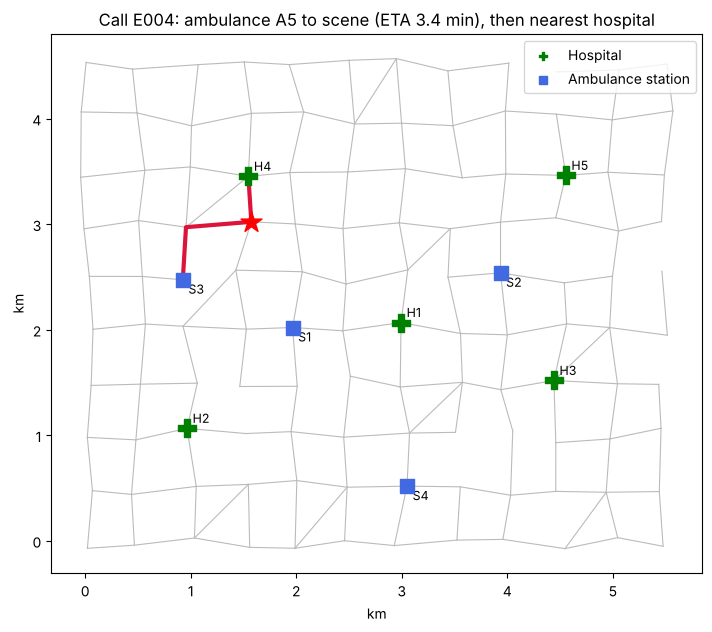

In [13]:
# Trace one dispatched call on the map
row = log.iloc[3]; req = emergencies_df.iloc[3]
free_demo = [Ambulance(a, n) for a, n in fleet_rows]
amb, eta, _ = select_fast(G, req.node_id, free_demo)
_, _, p_hosp, _ = nearest_target(G, req.node_id, set(hosp_nodes_list))
p_amb = dijkstra(G, amb.node, req.node_id).path
draw_city(G, nodes_df, hospitals_df, stations_df, path=p_amb + p_hosp, incident=req.node_id,
          title=f"Call {req.request_id}: ambulance {amb.aid} to scene (ETA {eta:.1f} min), then nearest hospital")

## 6. Performance evaluation

We evaluate three things the brief asks for: **execution time**, **computational complexity**, and **solution quality**.

**Method notes:** we use fixed random seeds so results are reproducible. We report *nodes expanded* alongside seconds, because seconds depend on the computer while expansions measure the algorithm itself. Timing uses `time.perf_counter` and averages over many trials.

### 6.1 Priority queue scaling (should be about O(n log n) for n inserts + n removals)

In [14]:
sizes, times = [1_000, 4_000, 16_000, 64_000, 256_000], []
for n in sizes:
    rs = [Emergency(str(i), random.random() * 100, 0, random.randint(1, 5)) for i in range(n)]
    t0 = time.perf_counter(); q = DispatchQueue("priority")
    for r in rs: q.push(r)
    while len(q): q.pop()
    times.append(time.perf_counter() - t0)
df_q = pd.DataFrame(dict(n=sizes, seconds=times))
df_q["us_per_n_log2n"] = df_q.seconds * 1e6 / (df_q.n * df_q.n.apply(math.log2))
display(df_q.round(4))
print("If the last column is roughly constant, time grows like n log n, as predicted.")

,n,seconds,us_per_n_log2n
0,1000,0.0008,0.0852
1,4000,0.0031,0.0657
2,16000,0.0183,0.0820
3,64000,0.1827,0.1788
4,256000,1.0672,0.2320


If the last column is roughly constant, time grows like n log n, as predicted.


### 6.2 Routing: Dijkstra vs A\* as the city grows

In [15]:
def bench_routing(rows_cols, pairs=40, seed=11):
    out = []
    for r, c in rows_cols:
        co, ed = generate_city(r, c, seed=3); g = graph_from(co, ed); ids = sorted(g.coords)
        rng = random.Random(seed); prs = [rng.sample(ids, 2) for _ in range(pairs)]
        res = {}
        for name, fn in (("dijkstra", dijkstra), ("astar", astar)):
            t0 = time.perf_counter(); rs = [fn(g, s, t) for s, t in prs]
            res[name] = ((time.perf_counter() - t0) / pairs * 1000, sum(x.expanded for x in rs) / pairs, [x.cost for x in rs])
        gap = max(abs(a - b) for a, b in zip(res["dijkstra"][2], res["astar"][2]))
        out.append(dict(V=g.n_nodes(), E=g.n_edges(),
                        dij_ms=res["dijkstra"][0], astar_ms=res["astar"][0],
                        dij_expanded=res["dijkstra"][1], astar_expanded=res["astar"][1],
                        expansion_ratio=res["dijkstra"][1] / res["astar"][1],
                        max_cost_gap=gap))
    return pd.DataFrame(out)

df_r = bench_routing([(10, 10), (20, 20), (30, 30), (45, 45), (60, 60), (80, 80)])
display(df_r.round(3))

,V,E,dij_ms,astar_ms,dij_expanded,astar_expanded,expansion_ratio,max_cost_gap
0,98,171,0.034,0.030,47.125,25.900,1.819,0.0
1,400,723,0.150,0.136,198.350,104.000,1.907,0.0
2,900,1652,0.304,0.232,366.700,166.850,2.198,0.0
3,2025,3795,1.031,0.904,1107.750,596.600,1.857,0.0
4,3600,6750,1.836,1.471,1803.000,900.925,2.001,0.0
5,6400,11990,3.307,2.480,3048.475,1662.850,1.833,0.0


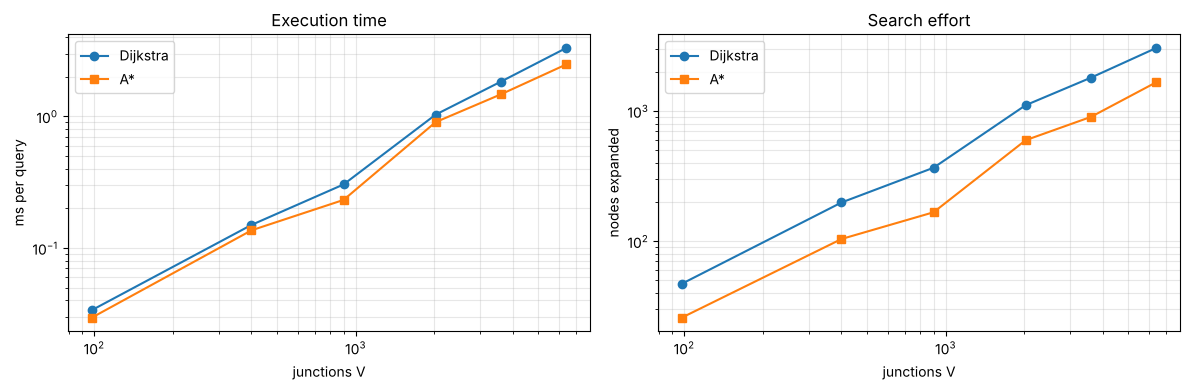

Empirical growth exponent on log-log plot: Dijkstra ~ V^1.11, A* ~ V^1.08  (n log n would give slightly above 1.0)
Max cost difference between the algorithms across all queries: 0.0


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(df_r.V, df_r.dij_ms, "o-", label="Dijkstra"); ax[0].loglog(df_r.V, df_r.astar_ms, "s-", label="A*")
ax[0].set_xlabel("junctions V"); ax[0].set_ylabel("ms per query"); ax[0].set_title("Execution time"); ax[0].legend(); ax[0].grid(alpha=.3, which="both")
ax[1].loglog(df_r.V, df_r.dij_expanded, "o-", label="Dijkstra"); ax[1].loglog(df_r.V, df_r.astar_expanded, "s-", label="A*")
ax[1].set_xlabel("junctions V"); ax[1].set_ylabel("nodes expanded"); ax[1].set_title("Search effort"); ax[1].legend(); ax[1].grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()
import numpy as np
slope = np.polyfit(np.log(df_r.V), np.log(df_r.dij_ms), 1)[0]; slope_a = np.polyfit(np.log(df_r.V), np.log(df_r.astar_ms), 1)[0]
print(f"Empirical growth exponent on log-log plot: Dijkstra ~ V^{slope:.2f}, A* ~ V^{slope_a:.2f}  (n log n would give slightly above 1.0)")
print("Max cost difference between the algorithms across all queries:", df_r.max_cost_gap.max())

**How to read the log-log plot:** if time is proportional to V^k, the line has slope k. A slope near 1 means roughly linear growth (slightly more because of the log factor). Compare the two lines, and compare them with the theory O((V+E) log V).

### 6.3 Ambulance selection: one search vs k searches

In [17]:
co, ed = generate_city(40, 40, seed=3); g40 = graph_from(co, ed); ids40 = sorted(g40.coords)
rows = []
for k in (2, 5, 10, 20, 40):
    rng = random.Random(k); res = {"fast": [0, 0.0], "naive": [0, 0.0]}; same = True
    for _ in range(30):
        free = [Ambulance(f"X{i}", n) for i, n in enumerate(rng.sample(ids40, k))]; inc = rng.choice(ids40)
        for name, fn in (("fast", select_fast), ("naive", select_naive)):
            t0 = time.perf_counter(); a, c, e = fn(g40, inc, free); res[name][1] += time.perf_counter() - t0; res[name][0] += e
            if name == "fast": c_fast = c
            else: same &= abs(c - c_fast) < 1e-9
    rows.append(dict(k_free_ambulances=k, fast_ms=res["fast"][1] / 30 * 1e3, naive_ms=res["naive"][1] / 30 * 1e3,
                     fast_expanded=res["fast"][0] / 30, naive_expanded=res["naive"][0] / 30, same_answer=same))
df_s = pd.DataFrame(rows); df_s["speedup"] = df_s.naive_ms / df_s.fast_ms; display(df_s.round(3))

,k_free_ambulances,fast_ms,naive_ms,fast_expanded,naive_expanded,same_answer,speedup
0,2,0.408,1.236,494.733,1544.567,True,3.030
1,5,0.182,3.076,206.867,3819.700,True,16.872
2,10,0.140,6.713,141.600,7882.833,True,47.912
3,20,0.085,13.155,77.300,15752.933,True,154.148
4,40,0.050,26.338,39.033,31613.000,True,532.002


**Observation:** the naive method's cost grows with k. The single search actually gets *cheaper* as k grows, because with more ambulances around, the first one is found sooner. Both always give the same ETA, so the faster method loses no quality.

### 6.4 Solution quality 1: is "closest on the map" really closest?

In [18]:
rng = random.Random(99); trials, diff, extra = 400, 0, []
ids = sorted(G.coords)
for _ in range(trials):
    free = [Ambulance(f"Q{i}", n) for i, n in enumerate(rng.sample(ids, 6))]; inc = rng.choice(ids)
    a1, c1, _ = select_fast(G, inc, free); a2, c2, _ = select_straightline(G, inc, free)
    if a1.aid != a2.aid: diff += 1; extra.append(c2 - c1)
print(f"Straight-line choice differs from true-nearest in {diff}/{trials} cases ({100*diff/trials:.1f}%).")
if extra: print(f"When it differs, the patient waits {np.mean(extra):.2f} min longer on average (max {max(extra):.2f} min).")

Straight-line choice differs from true-nearest in 53/400 cases (13.2%).
When it differs, the patient waits 1.20 min longer on average (max 3.81 min).


### 6.5 Solution quality 2: does the prioritisation policy matter?

We simulate **30 different 4-hour days** (different random calls) under each policy on the Arua network, with a **busy scenario** (60 calls, 8 ambulances) and a **stressed scenario** (70 calls, 6 ambulances, e.g. a market-day surge with two vehicles in the garage). We report mean response by severity group and the worst wait.

In [19]:
def run_policy_study(n_calls, fleet_rows_used, days=30, aging=AGING):
    out = []
    for policy in ("fifo", "severity", "priority"):
        frames = []
        for d in range(days):
            em = generate_emergencies(G.coords, n_calls, 240, seed=1000 + d)
            lg, _ = simulate(G, hosp_nodes_list, fleet_rows_used, to_requests(em), policy=policy, aging=aging)
            frames.append(lg)
        all_ = pd.concat(frames)
        pts = all_.severity.map(SEVERITY_POINTS)
        out.append(dict(policy=policy,
                        mean_all=all_.response.mean(),
                        sev5=all_[all_.severity == 5].response.mean(),
                        sev4=all_[all_.severity == 4].response.mean(),
                        sev1_2=all_[all_.severity <= 2].response.mean(),
                        worst_wait=all_.response.max(),
                        p90=all_.response.quantile(.9),
                        weighted_by_severity=(all_.response * pts).sum() / pts.sum()))
    return pd.DataFrame(out).set_index("policy")

print("BUSY scenario: 60 calls, 8 ambulances"); busy = run_policy_study(60, fleet_rows); display(busy.round(2))
print("STRESSED scenario: 70 calls, 6 ambulances"); stress = run_policy_study(70, fleet_rows[:6]); display(stress.round(2))

BUSY scenario: 60 calls, 8 ambulances


,mean_all,sev5,sev4,sev1_2,worst_wait,p90,weighted_by_severity
policy,,,,,,,
fifo,10.75,10.92,10.39,10.76,51.98,21.32,10.73
severity,10.73,8.63,8.83,12.81,136.26,19.20,9.64
priority,10.68,8.58,8.86,12.32,65.42,20.07,9.77


STRESSED scenario: 70 calls, 6 ambulances


,mean_all,sev5,sev4,sev1_2,worst_wait,p90,weighted_by_severity
policy,,,,,,,
fifo,46.82,45.20,46.17,47.18,150.11,86.46,46.48
severity,45.94,12.45,14.51,88.25,266.97,135.63,25.78
priority,46.64,12.61,24.11,67.94,151.01,99.84,33.93


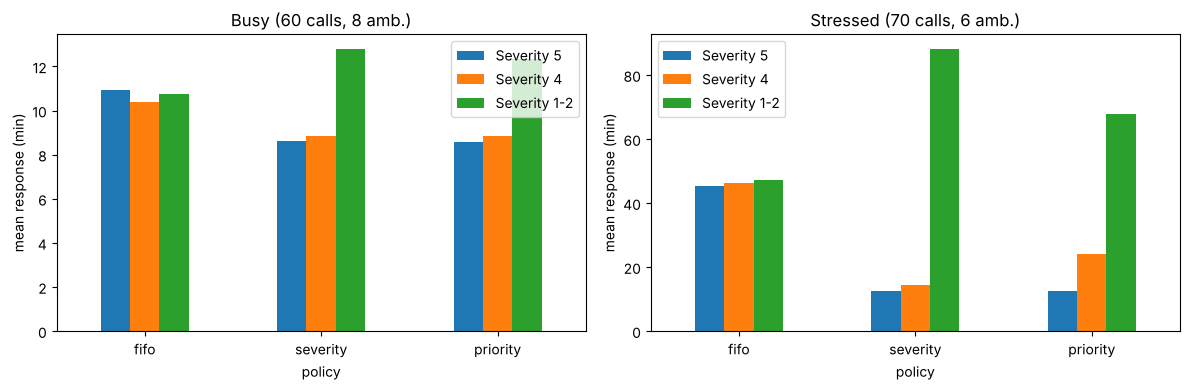

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, df, name in zip(axs, (busy, stress), ("Busy (60 calls, 8 amb.)", "Stressed (70 calls, 6 amb.)")):
    df[["sev5", "sev4", "sev1_2"]].plot.bar(ax=ax, rot=0); ax.set_title(name); ax.set_ylabel("mean response (min)")
    ax.legend(["Severity 5", "Severity 4", "Severity 1-2"])
plt.tight_layout(); plt.show()

### 6.6 Sensitivity: how should we choose the aging weight?

,sev5,sev1_2,worst,p90
aging,,,,
0.00,12.45,88.25,266.97,135.63
0.25,12.54,84.88,218.21,123.77
0.50,12.62,77.00,174.32,111.08
1.00,12.61,67.94,151.01,99.84
2.00,19.39,58.72,152.16,89.17
4.00,29.28,53.67,145.93,87.85


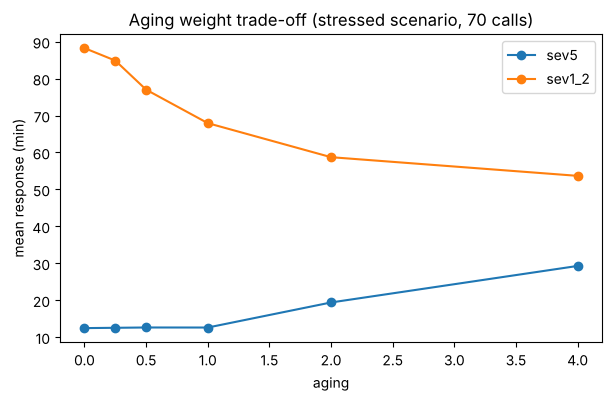

In [21]:
rows = []
for a in (0.0, 0.25, 0.5, 1.0, 2.0, 4.0):
    frames = []
    for d in range(30):
        em = generate_emergencies(G.coords, 70, 240, seed=1000 + d)
        lg, _ = simulate(G, hosp_nodes_list, fleet_rows[:6], to_requests(em), policy="priority", aging=a); frames.append(lg)
    al = pd.concat(frames)
    rows.append(dict(aging=a, sev5=al[al.severity == 5].response.mean(), sev1_2=al[al.severity <= 2].response.mean(),
                     worst=al.response.max(), p90=al.response.quantile(.9)))
df_a = pd.DataFrame(rows).set_index("aging"); display(df_a.round(2))
df_a[["sev5", "sev1_2"]].plot(marker="o", figsize=(7, 4), title="Aging weight trade-off (stressed scenario, 70 calls)"); plt.ylabel("mean response (min)"); plt.show()

## 7. Complexity summary and limitations

| Component | Algorithm | Time | Space |
|---|---|---|---|
| Enqueue / dequeue emergency | Binary heap with static aging key | O(log n) each | O(n) |
| Route (point to point) | Dijkstra, binary heap | O((V+E) log V) | O(V) |
| Route (point to point) | A\*, admissible heuristic | O((V+E) log V) worst case, much less in practice | O(V) |
| Ambulance selection | One early-stopping Dijkstra from the incident | O((V+E) log V), independent of k in the worst case | O(V) |
| Naive selection | k Dijkstra runs | O(k (V+E) log V) | O(V) |
| Whole simulation | per call: 1 pop + 1 selection + 1 hospital search | O(m (V+E) log V) for m calls | O(V + m) |

**Limitations (be honest in the report):** (1) travel times are a static traffic snapshot, so real-time congestion would need dynamic weights; (2) ambulances wait at the hospital after drop-off rather than returning to a station; (3) hospital capacity and specialisation are not modelled; (4) one patient per ambulance; (5) the data is simulated; (6) results are from one synthetic city layout.

**Possible extensions:** contraction hierarchies or landmarks (ALT) for much faster routing; relocating idle ambulances to coverage-optimal stations; hospital bed availability; time-dependent edge weights; real OpenStreetMap data for Arua through `osmnx`.